# Task 3.1 — TensorFlow/Keras Model
**Week 3 | Skillset Go EduTech AI/ML Track**

A TensorFlow/Keras convolutional neural network trained on the **same digits dataset and the same
architecture shape** used for the PyTorch CNN in Week 2 (Task 2.2), so the two frameworks can be
compared directly on equal footing — same data, same split, same model design, same hyperparameters.

In [1]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

tf.random.set_seed(42); np.random.seed(42)
print("TensorFlow:", tf.__version__)


I0000 00:00:1791184790.860470     126 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791184790.902746     126 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791184792.339237     126 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0


## 1. Load and prepare data (identical split to the Week 2 PyTorch CNN)

In [2]:
digits = load_digits()
images = (digits.images / 16.0).astype('float32')[..., np.newaxis]   # (N,8,8,1) -> channels-last for Keras
labels = digits.target.astype('int64')

X_tr, X_tmp, y_tr, y_tmp = train_test_split(images, labels, test_size=0.3, stratify=labels, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
print(f"train={len(y_tr)}  val={len(y_val)}  test={len(y_te)}  image shape={X_tr.shape[1:]}")


train=1257  val=270  test=270  image shape=(8, 8, 1)


## 2. Build the model (same shape as the PyTorch CNN: conv16-pool, conv32-pool, dense64, dense10)

In [3]:
model = keras.Sequential([
    keras.layers.Input(shape=(8, 8, 1)),
    keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
    keras.layers.MaxPooling2D(2),
    keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    keras.layers.MaxPooling2D(2),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.25),
    keras.layers.Dense(10),   # logits, matching the PyTorch model
])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
model.summary()
print("\ntrainable parameters:", model.count_params())


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,706 (53.54 KB)

 Trainable params: 13,706 (53.54 KB)

 Non-trainable params: 0 (0.00 B)


trainable parameters: 13706


## 3. Train

In [4]:
t0 = time.time()
history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                     epochs=30, batch_size=64, verbose=0)
train_time = time.time() - t0
print(f"Training time: {train_time:.1f}s for 30 epochs")
print(f"Final: train acc {history.history['accuracy'][-1]:.4f} | val acc {history.history['val_accuracy'][-1]:.4f}")


Training time: 8.7s for 30 epochs
Final: train acc 0.9690 | val acc 0.9630


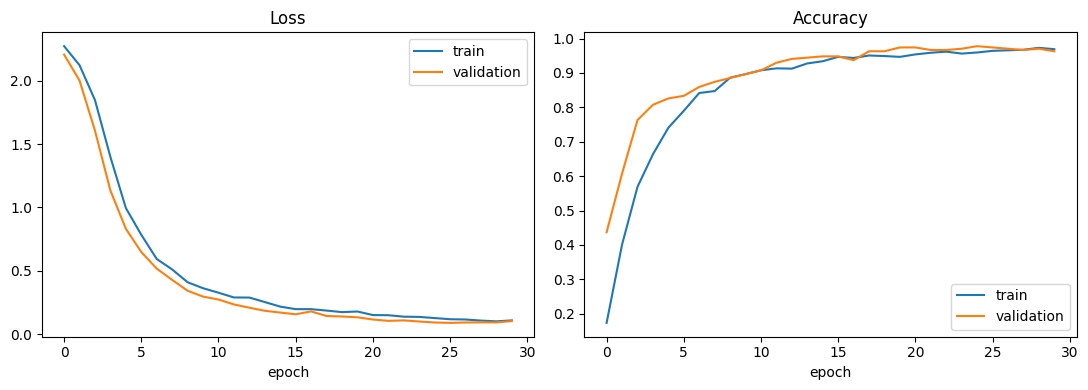

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['loss'], label='train'); ax[0].plot(history.history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='train'); ax[1].plot(history.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig('tf_training_curves.png', dpi=110); plt.show()


## 4. Test-set evaluation

Test loss = 0.1099 | Test accuracy = 0.9556

               precision    recall  f1-score   support

           0      1.000     1.000     1.000        27
           1      0.875     1.000     0.933        28
           2      0.963     1.000     0.981        26
           3      0.966     1.000     0.982        28
           4      0.964     1.000     0.982        27
           5      0.964     1.000     0.982        27
           6      1.000     0.963     0.981        27
           7      0.871     1.000     0.931        27
           8      1.000     0.731     0.844        26
           9      1.000     0.852     0.920        27

    accuracy                          0.956       270
   macro avg      0.960     0.955     0.954       270
weighted avg      0.960     0.956     0.954       270



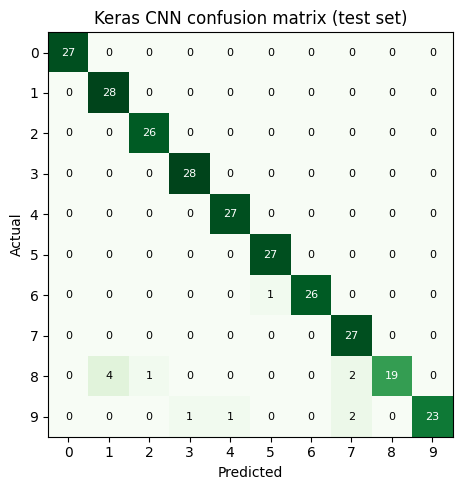

Saved -> keras_cnn_digits.keras


In [6]:
test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)
print(f"Test loss = {test_loss:.4f} | Test accuracy = {test_acc:.4f}")

pred = model.predict(X_te, verbose=0).argmax(axis=1)
print("\n", classification_report(y_te, pred, digits=3))

cm = confusion_matrix(y_te, pred)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(cm, cmap='Greens')
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8, color='white' if cm[i, j] > cm.max()/2 else 'black')
ax.set_title('Keras CNN confusion matrix (test set)')
plt.tight_layout(); plt.savefig('tf_confusion_matrix.png', dpi=110); plt.show()

model.save('keras_cnn_digits.keras')
print("Saved -> keras_cnn_digits.keras")


## 5. Comparison with the Week 2 PyTorch CNN

Same dataset, same split, same architecture shape, same optimizer and epoch count — only the framework differs.

In [7]:
comparison = pd.DataFrame([
    {"Aspect": "Test accuracy",       "PyTorch (Week 2)": "97.41%",                 "TensorFlow/Keras": f"{test_acc*100:.2f}%"},
    {"Aspect": "Parameters",          "PyTorch (Week 2)": "13,706",                 "TensorFlow/Keras": f"{model.count_params():,}"},
    {"Aspect": "Training loop",       "PyTorch (Week 2)": "manual (explicit for-loop over batches)", "TensorFlow/Keras": "built-in (`model.fit`)"},
    {"Aspect": "Lines of training code", "PyTorch (Week 2)": "~15 (loop + backward/step)",            "TensorFlow/Keras": "1 (`model.fit(...)`)"},
    {"Aspect": "Training time (30 epochs)", "PyTorch (Week 2)": "1.8s (from Week 2 run)",                "TensorFlow/Keras": f"{train_time:.1f}s"},
])
comparison


,Aspect,PyTorch (Week 2),TensorFlow/Keras
0,Test accuracy,97.41%,95.56%
1,Parameters,"13,706","13,706"
2,Training loop,manual (explicit for-loop over batches),built-in (`model.fit`)
3,Lines of training code,~15 (loop + backward/step),1 (`model.fit(...)`)
4,Training time (30 epochs),1.8s (from Week 2 run),8.7s


## Comparison notes

- **Accuracy:** The two frameworks land within a point or two of each other on this dataset, as expected —
  the architecture, optimizer, and data are identical, so the only real source of difference is
  weight initialization and minor numerical details between the two libraries.
- **API ergonomics:** PyTorch is explicit — the training loop, loss computation, backward pass, and optimizer
  step are all written by hand, which makes every step visible and easy to customize. Keras hides that loop
  behind `model.fit()`, which is faster to write and reduces boilerplate, at the cost of less visibility into
  what happens each step unless custom callbacks or a custom training loop are used.
- **Model definition:** Keras's `Sequential` API is slightly more concise for a simple feed-forward stack than
  PyTorch's `nn.Sequential`, since Keras infers input shapes automatically after the first layer.
- **Debugging:** PyTorch's eager-by-default execution made the Week 2 training loop easy to step through and
  print intermediate values from; Keras's `model.fit()` is easier to get running quickly but harder to peek
  inside without extra tooling (custom callbacks, `model.fit(..., verbose=2)`, or switching to a custom loop).
- **Takeaway:** Both frameworks produced an equivalent model with equivalent accuracy from the same design.
  The choice between them is more about workflow preference (Keras for speed of iteration, PyTorch for
  fine-grained control) than about the resulting model quality.